In [16]:
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
dosya_yolu = 'degerlendirme_veri.xlsx'

In [18]:
ogrenciler_df = pd.read_excel(dosya_yolu, sheet_name='Ogrenciler')
sinav_df = pd.read_excel(dosya_yolu, sheet_name='Gunluk_Sinav')
degerlendirme_df = pd.read_excel(dosya_yolu, sheet_name='Gunluk_Degerlendirme')

## 1. Öğrencilerin gruplara dağılım

Grup
A    17
B    17
C    16
Name: count, dtype: int64


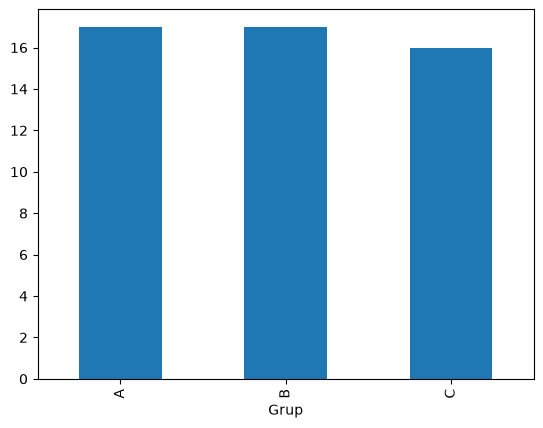

In [19]:
grup_sayisi = ogrenciler_df['Grup'].value_counts()
print(grup_sayisi)

grup_sayisi.plot(kind='bar')
plt.show()

## 2. Normalizasyon

In [ ]:
df = sinav_df.merge(degerlendirme_df, on=['Tarih', 'No'])
df = df.merge(ogrenciler_df, on='No')

df['Not_norm'] = (df['Not'] - df['Not'].min()) / (df['Not'].max() - df['Not'].min())
df['Puan_norm'] = (df['Puan'] - df['Puan'].min()) / (df['Puan'].max() - df['Puan'].min())
df.head()

,Tarih,No,Not,Puan,Ad Soyad,Grup,Not_norm,Puan_norm
0,2022-10-10,1,50.0,3,Ahmet Yıldırım,A,0.5,0.333333
1,2022-10-10,2,100.0,6,Mehmet Demir,B,1.0,0.666667
2,2022-10-10,3,100.0,6,Ayşe Kaya,C,1.0,0.666667
3,2022-10-10,4,100.0,6,Fatma Şahin,A,1.0,0.666667
4,2022-10-10,5,100.0,6,Hasan Arslan,B,1.0,0.666667


## 3. Kişinin başarı ölçüsü

In [21]:
df['Basari'] = df['Not_norm'] * 0.7 + df['Puan_norm'] * 0.3
df.head()

,Tarih,No,Not,Puan,Ad Soyad,Grup,Not_norm,Puan_norm,Basari
0,2022-10-10,1,50.0,3,Ahmet Yıldırım,A,0.5,0.333333,0.45
1,2022-10-10,2,100.0,6,Mehmet Demir,B,1.0,0.666667,0.90
2,2022-10-10,3,100.0,6,Ayşe Kaya,C,1.0,0.666667,0.90
3,2022-10-10,4,100.0,6,Fatma Şahin,A,1.0,0.666667,0.90
4,2022-10-10,5,100.0,6,Hasan Arslan,B,1.0,0.666667,0.90


## 4. En başarılı N öğrenci

In [22]:
N = 5

ogrenci_basari = df.groupby('Ad Soyad')['Basari'].mean().round(4)

# keep='all' -> aynı puanı alanlar da listeye girer
print(ogrenci_basari.nlargest(N, keep='all'))

Ad Soyad
Ahmetcan Karakaya    0.8949
Ayşe Kaya            0.8949
Barış Kurt           0.8949
Cemal Sezer          0.8949
Doğan Güler          0.8949
Fatma Şahin          0.8949
Kadir Kılıç          0.8949
Levent Güney         0.8949
Metin Baştürk        0.8949
Volkan Ersoy         0.8949
Name: Basari, dtype: float64


## 5. En başarılı grup

Grup
A    0.654059
B    0.674344
C    0.638168
Name: Basari, dtype: float64
En başarılı grup: B


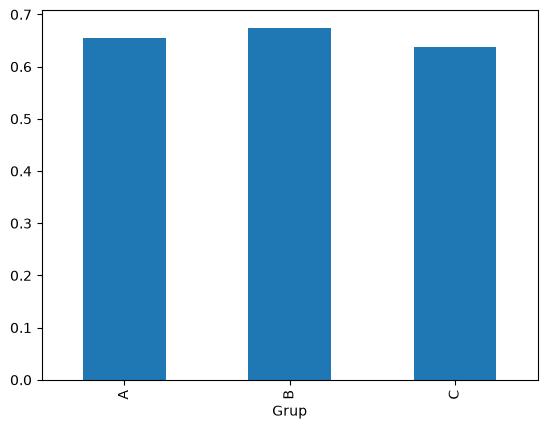

In [23]:
grup_basari = df.groupby('Grup')['Basari'].mean()
print(grup_basari)
print('En başarılı grup:', grup_basari.idxmax())

grup_basari.plot(kind='bar')
plt.show()

## 6. Grupların verili tarihe göre başarı grafiği

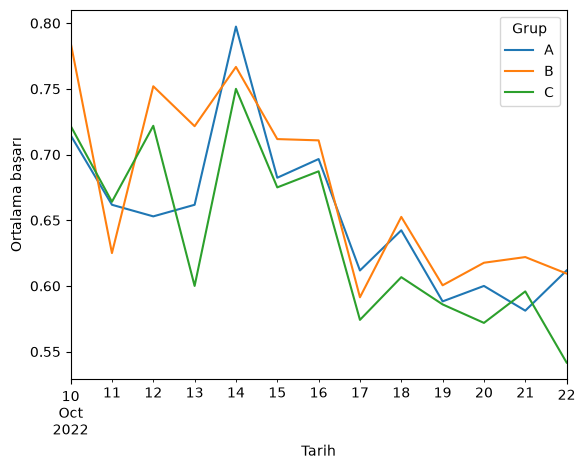

In [24]:
df.groupby(['Tarih', 'Grup'])['Basari'].mean().unstack().plot()
plt.ylabel('Ortalama başarı')
plt.show()

## 7. Günlük sınav ortalamasının değişimi, grafiği

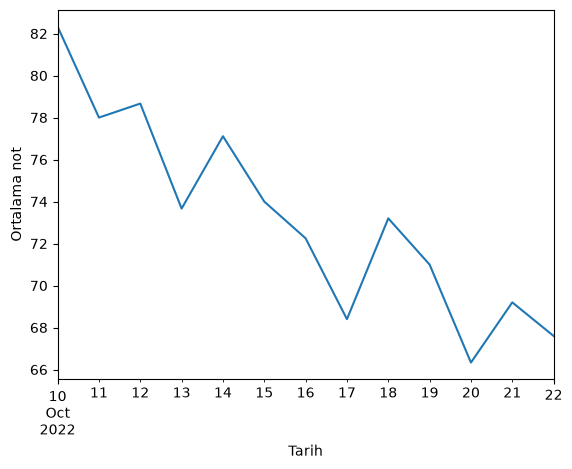

In [25]:
df.groupby('Tarih')['Not'].mean().plot()
plt.ylabel('Ortalama not')
plt.show()

## 8. Öğrencileri, Sınav Notu ve Değerlendirme verilerinin Tanımlayıcı İstatistiği

In [26]:
kolonlar = ['Not', 'Puan']
gruplu = df.groupby('Ad Soyad')[kolonlar]

ortalama = gruplu.mean()
medyan = gruplu.median()
mod = gruplu.agg(lambda x: x.mode()[0])   # birden fazla mod varsa ilkini al
std = gruplu.std()

istatistik = pd.concat([ortalama, medyan, mod, std], axis=1,
                       keys=['Ortalama', 'Medyan', 'Mod', 'Std'])
istatistik.head(10)

Ortalama            Medyan          Mod             Std  \
                          Not      Puan     Not Puan     Not Puan        Not   
Ad Soyad                                                                       
Ahmet Yıldırım      67.674615  4.000000   66.67  4.0   66.67    4  24.890936   
Ahmetcan Karakaya  100.000000  5.846154  100.00  6.0  100.00    5   0.000000   
Ali Güneş           88.205385  5.076923  100.00  5.0  100.00    6  28.434751   
Ayhan Kocaman       98.461538  5.769231  100.00  6.0  100.00    6   5.547002   
Ayşe Kaya          100.000000  5.846154  100.00  6.0  100.00    5   0.000000   
Barış Kurt         100.000000  5.846154  100.00  6.0  100.00    5   0.000000   
Burak Demirtaş      74.359231  4.461538  100.00  5.0  100.00    5  43.362860   
Caner Özdemir        3.846154  0.153846    0.00  0.0    0.00    0  13.867505   
Cemal Sezer        100.000000  5.846154  100.00  6.0  100.00    5   0.000000   
Cengiz Özkan        26.709231  1.538462    0.00  0.0    0.00    0  38.980259   

                             
                       Puan  
Ad Soyad                     
Ahmet Yıldırım     1.870829  
Ahmetcan Karakaya  1.463224  
Ali Güneş          1.934836  
Ayhan Kocaman      1.535895  
Ayşe Kaya          1.463224  
Barış Kurt         1.463224  
Burak Demirtaş     2.933013  
Caner Özdemir      0.554700  
Cemal Sezer        1.463224  
Cengiz Özkan       2.221688

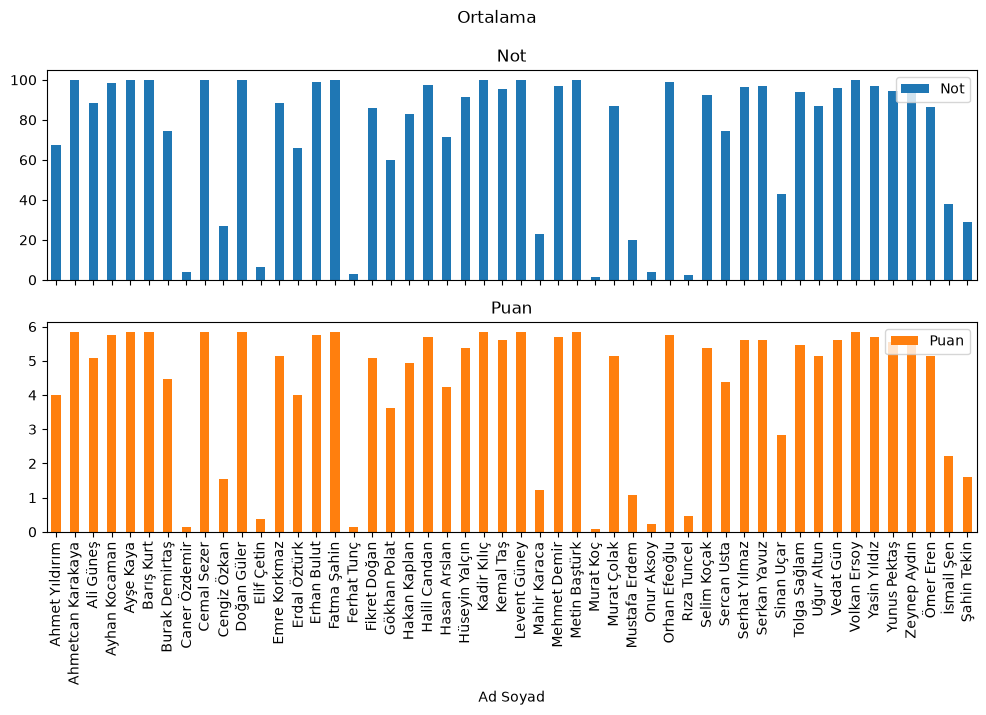

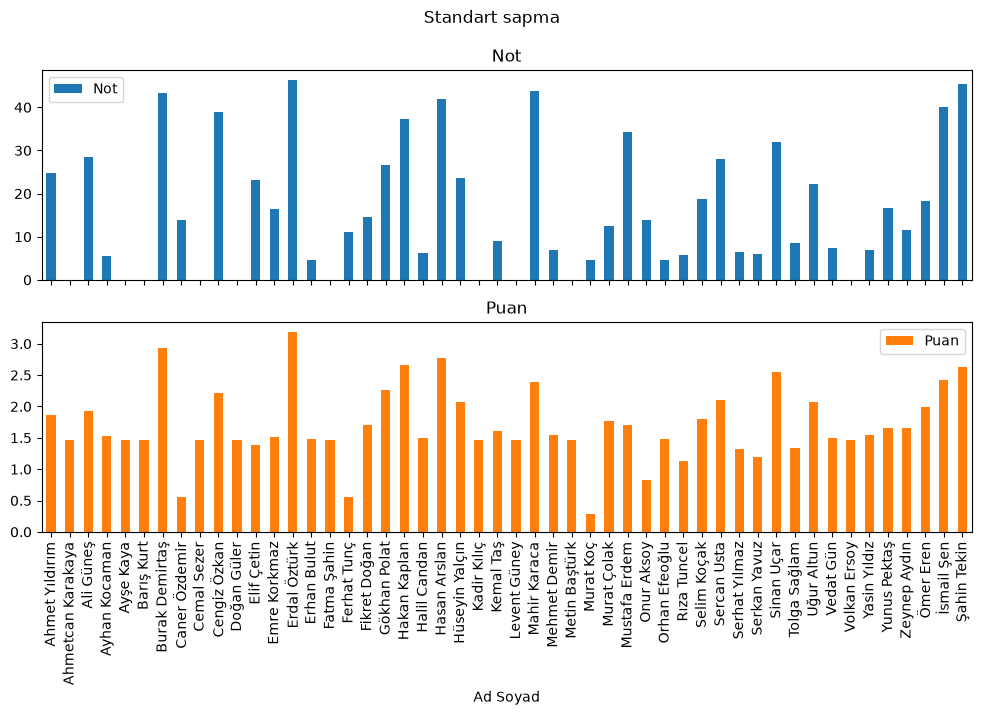

In [27]:
ortalama.plot(kind='bar', subplots=True, figsize=(12, 6), title='Ortalama')
plt.show()

std.plot(kind='bar', subplots=True, figsize=(12, 6), title='Standart sapma')
plt.show()

## 9. Soru: Sınav notu ile değerlendirme puanı arasında ilişki var mı?

Korelasyon: 0.8895814718287661


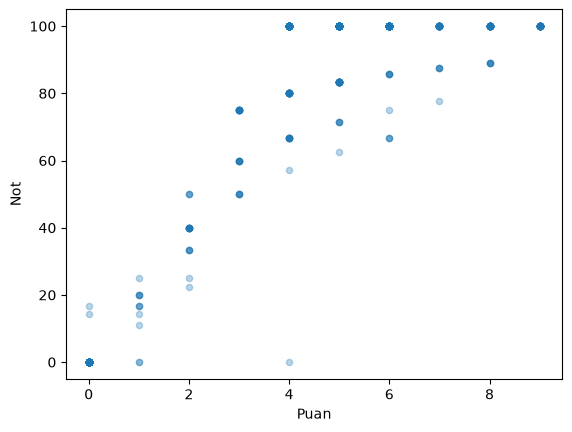

In [28]:
print('Korelasyon:', df['Not'].corr(df['Puan']))

df.plot(kind='scatter', x='Puan', y='Not', alpha=0.3)
plt.show()

**Yanıt:** Evet, güçlü pozitif ilişki var (korelasyon ≈ 0.89).

## 10. Soru: Hangi tarihte ortalama başarı en yüksekti?

In [29]:
gunluk_basari = df.groupby('Tarih')['Basari'].mean()
print('En yüksek:', gunluk_basari.idxmax(), '->', round(gunluk_basari.max(), 3))
print('En düşük :', gunluk_basari.idxmin(), '->', round(gunluk_basari.min(), 3))

En yüksek: 2022-10-14 00:00:00 -> 0.772
En düşük : 2022-10-22 00:00:00 -> 0.589


**Yanıt:** En başarılı gün 14 Ekim 2022 (≈ 0.77); sonraki günlerde başarı düşüyor.